### Case Study: **São Tomé**

*Primitive to Intermediate - Alkaline*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/sao_tome/sao_tome.ipynb)

São Tomé is one of four ocean islands that form the oceanic sector of the Cameroon volcanic line in West Africa. They form a coherent sequence from primitive to intermediate compositions which can be modelled through fractional crystallisation.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/sao_tome) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/sao_tome/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [ ]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel(
    mode='alkaline'
)

# Load the OJP data suite
model.load_data_suite('./sao_tome.xlsx')

# Select samples to form the projected LLOD
model.select_initial_composition([None, 'auto', 'auto', 'auto', None, None])

Primary       : n/a
Primitive     : 'ST18' [auto]
Basic         : 'ST96' [auto]
Intermediate  : 'ST55' [auto]
Evolved       : n/a
End           : n/a
3/6 phases have been set with user-provided initial compositions.


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

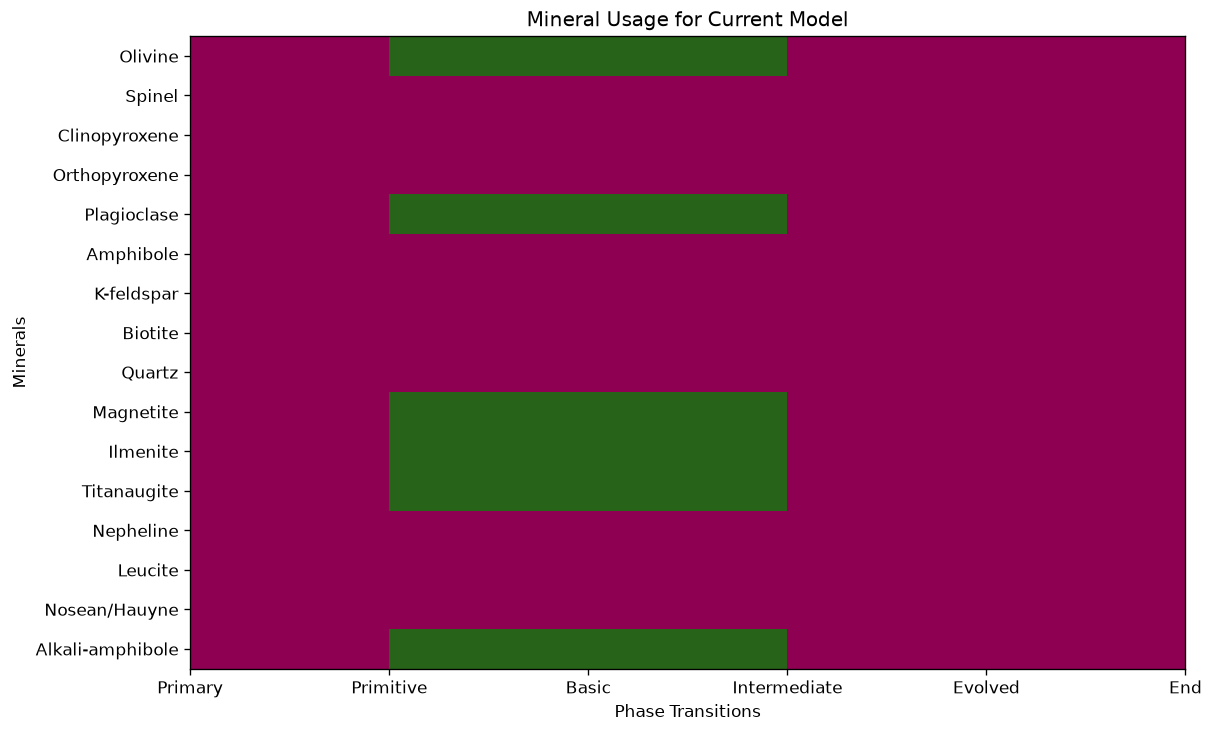

In [58]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    __=False,
    __olivine=True,
    __titanaugite=True,
    __ilmenite=True,
    __magnetite=True,
    __plagioclase=True,
    __alkali_amphibole=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

**Optimisation**

In [59]:
# Run stages 2 - 3 (primitve-basic-intermediate) of the model sequentially
model.run(2)
model.run(3)

> Optimisation completed with cost = 1.08 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.56 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [60]:
model.summary()

                        P-B        B-I     |     Total   
----------------------------------------------------------------
            Type  |    Majors     Majors   |            
            Cost  |      1.08       0.56   |            
----------------------------------------------------------------
               F  |        35         47   |       100    %
         Olivine  |    28.074     13.345   |    21.210    wt.%
          Spinel  |                        |              wt.%
     Plagioclase  |     0.306     25.689   |    12.135    wt.%
      K-feldspar  |                        |              wt.%
         Biotite  |                        |              wt.%
       Magnetite  |     1.316      6.814   |     3.879    wt.%
        Ilmenite  |     5.007      4.078   |     4.574    wt.%
     Titanaugite  |    64.496     47.062   |    56.371    wt.%
       Nepheline  |                        |              wt.%
         Leucite  |                        |              wt.%
   Nosea

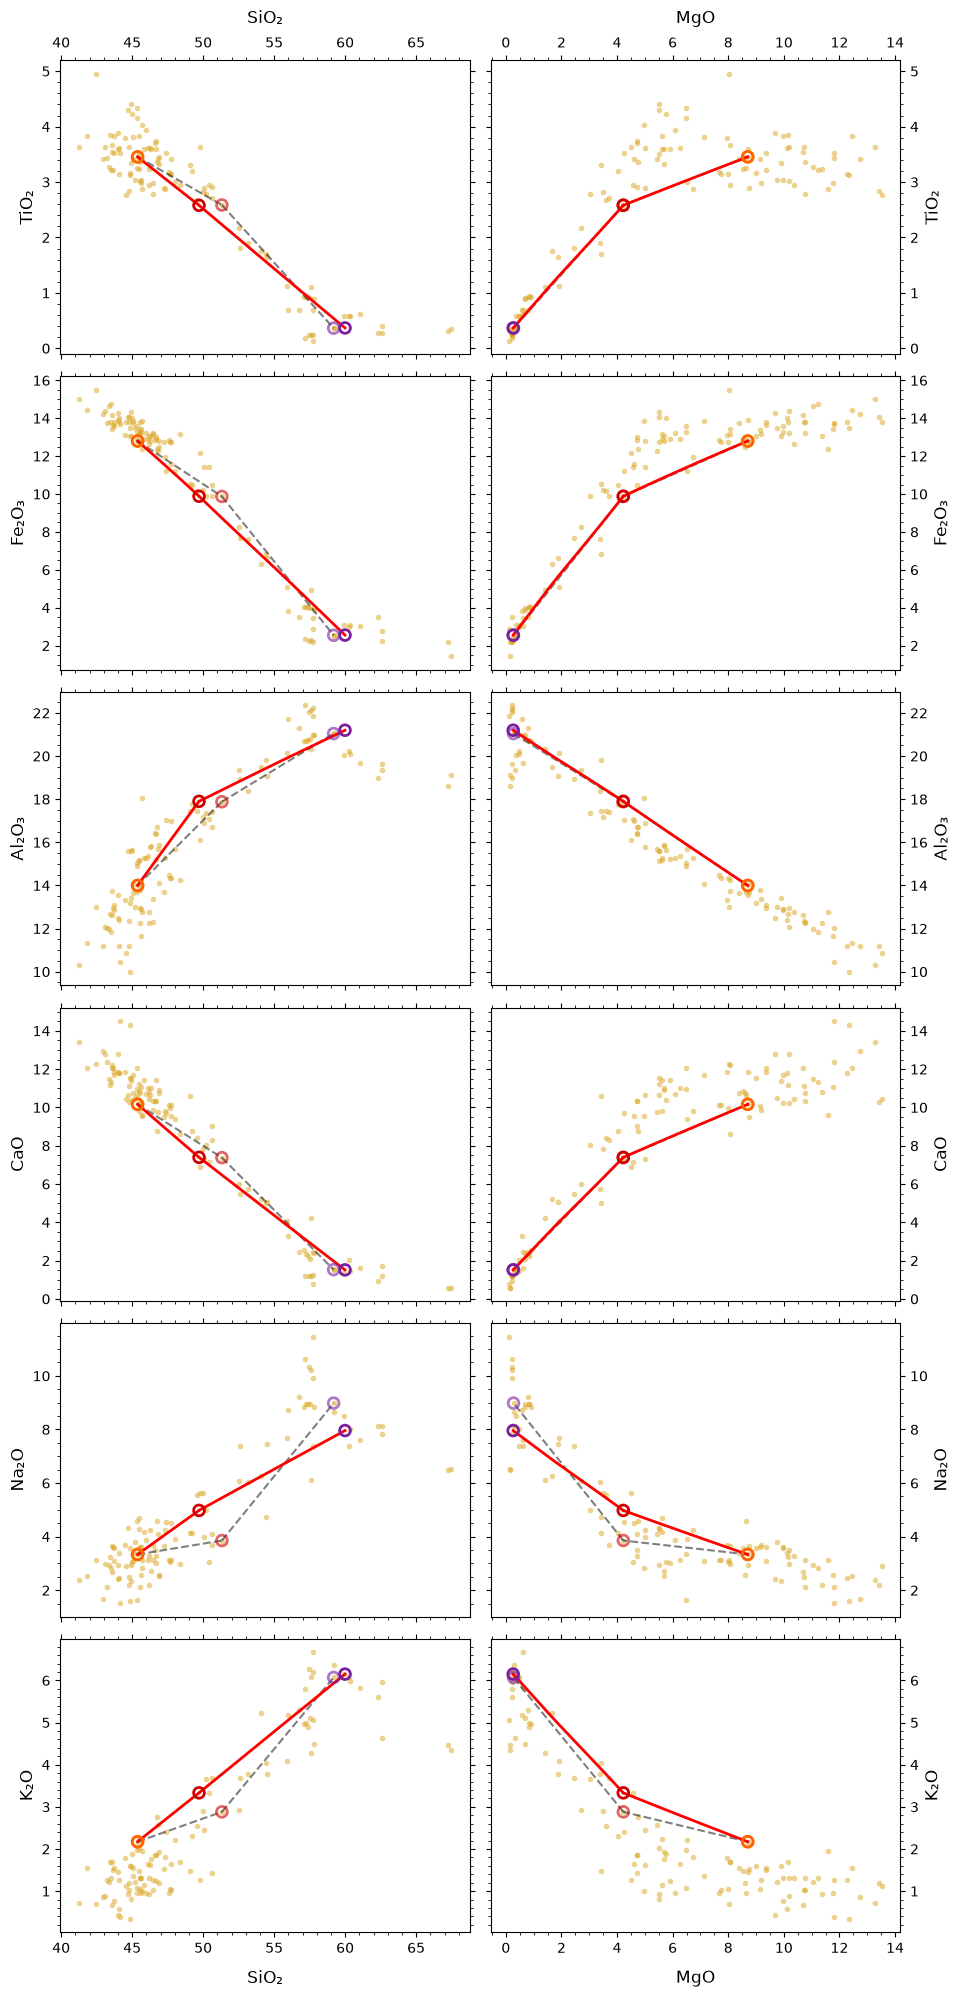

In [61]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

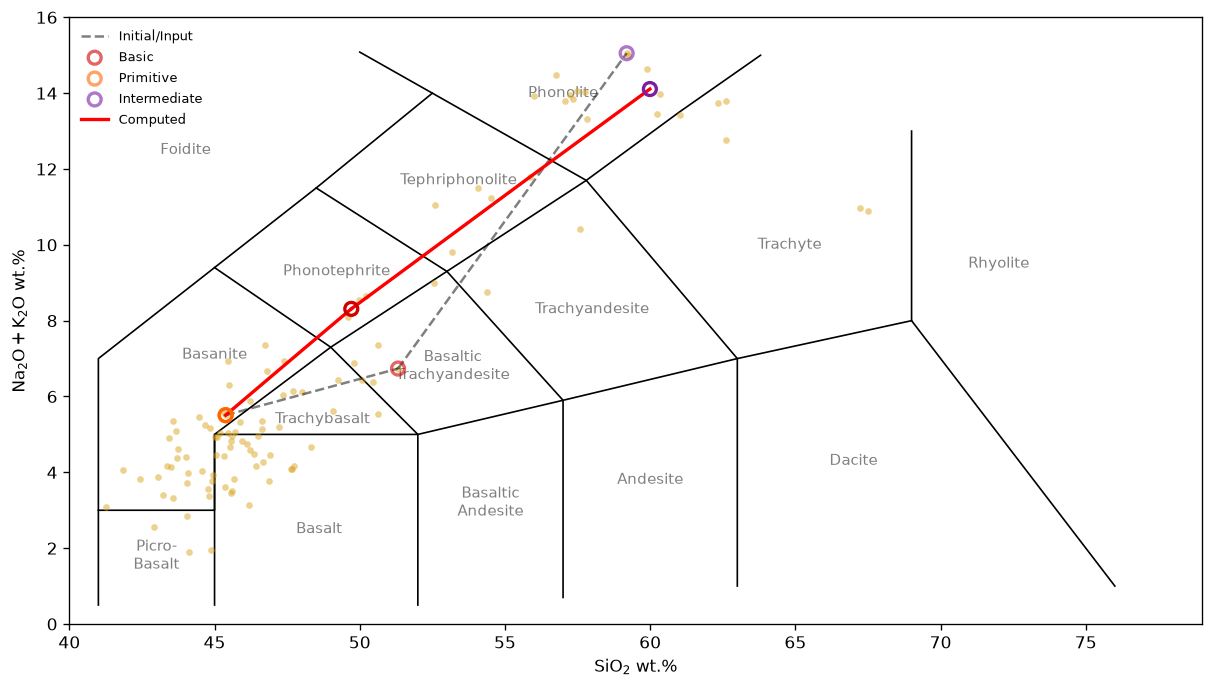

In [62]:
from hades.visuals import tas
tas(
    model, 
    filename="./outputs/tas_diagram.png"
)

**Trace Element Modelling**

To model trace elements, we perturb the optimal solution found above with your chosen wt.%s of accessory minerals. Hades re-models fractional crystallisation with the new bulk composition and outputs the trace element results.

We can use trial-and-error to find the best-fitting accessory mineral proportions, utilising the ``harker()`` function to visualise the results.

Trace element analyses were run. Using trace results for mineral proportions.
Trace element analyses were run. Using trace results for mineral proportions.


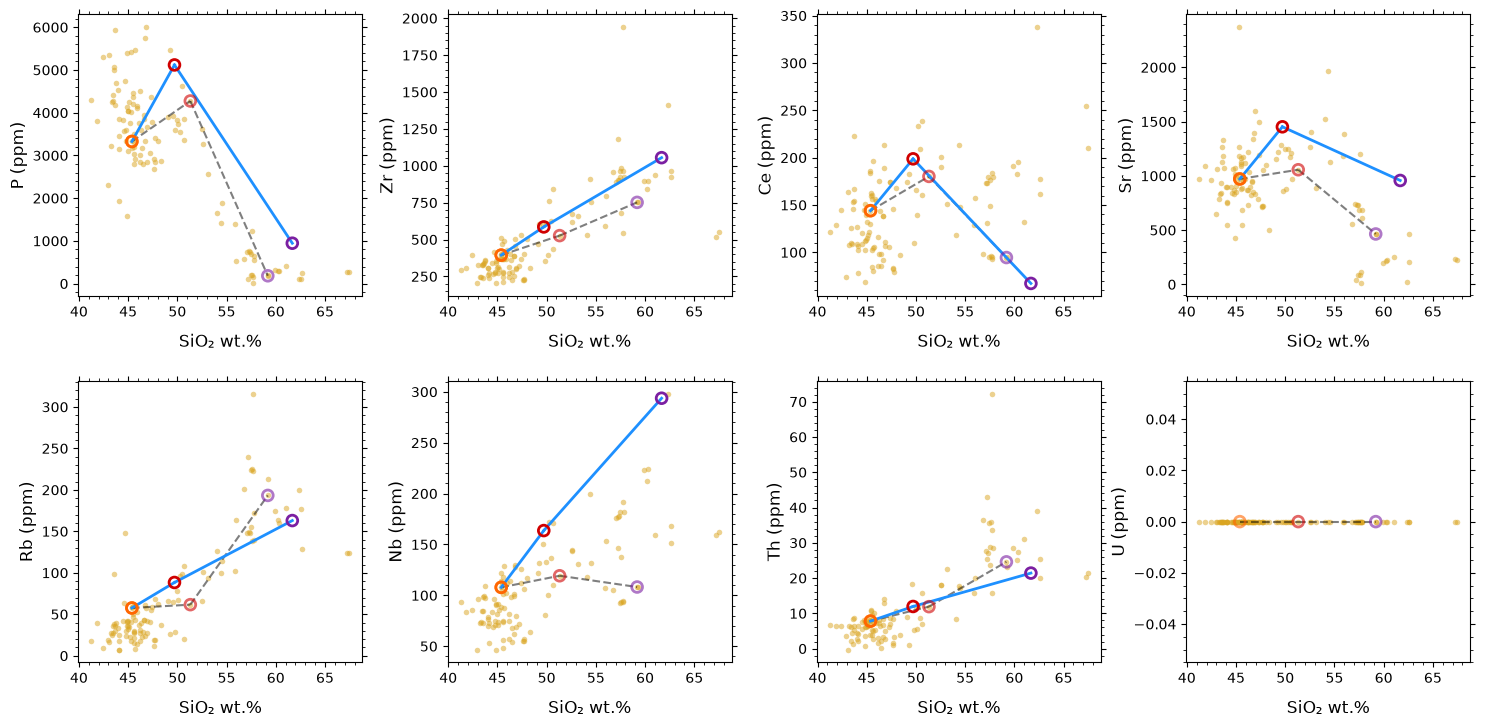

In [63]:
# For each stage, we provide the wt.% of apatite, zircon, monazite and allanite

# No accessory minerals in the primitive stage
model.runTraces(2)
# 5 wt.% apatite in the basic-intermediate stage
model.runTraces(3, [5, 0, 0, 0])

from hades.visuals import harker
harker(
    model, 
    y_order=['P', 'Zr', 'Ce', 'Sr', 'Rb', 'Nb', 'Th', 'U'], 
    nrows=2,
    filename="./outputs/harker_plots.png"
)

We can also re-visualise the bivariate diagrams with the trace modelled results (``mode='traces'``) to see the impact on major oxide elements.

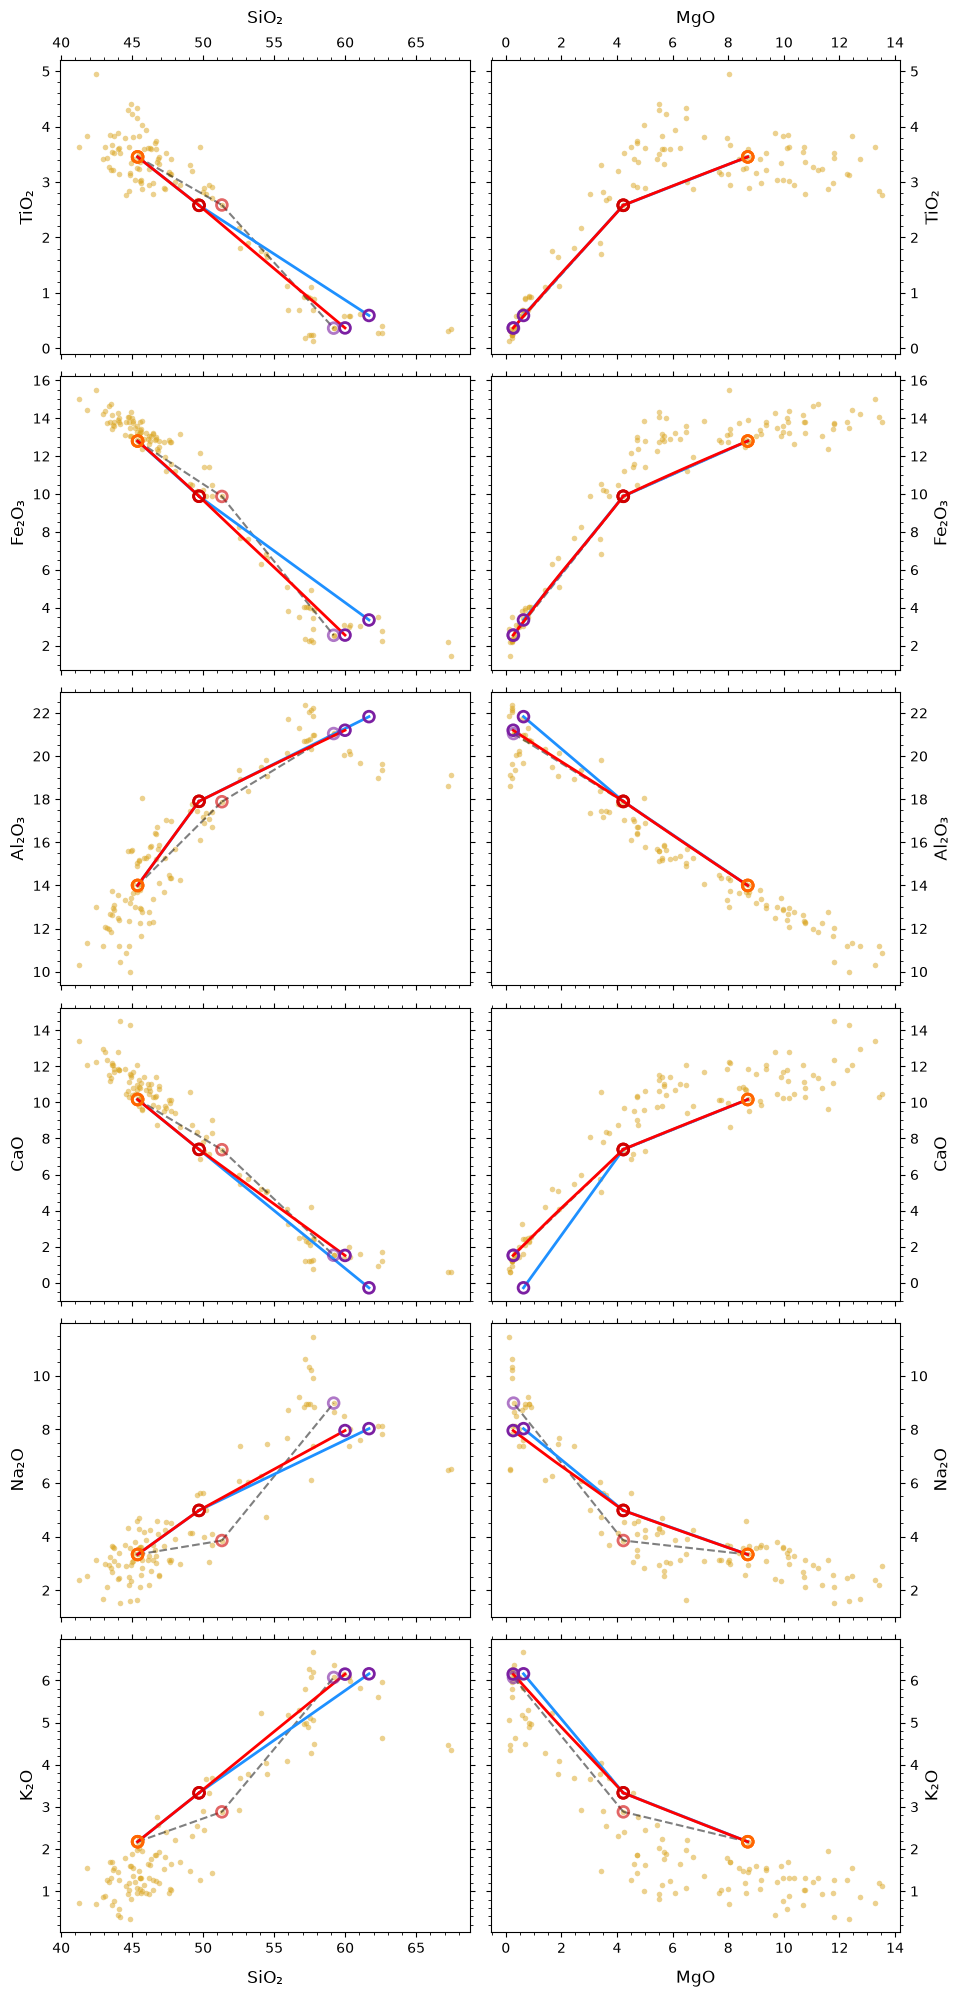

In [64]:
bivar(
    model, 
    mode='traces',
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots_trace_elements.png',
)

**Export Results**

Note that we can export results prior to or without trace element modelling, which will omit such results from the output files.

In [65]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [66]:
model.save_config('./sao_tome.hades')

Successfully saved configuration to ./sao_tome.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [67]:
model = Obol.newModel()
model.load_config('./sao_tome.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [68]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default